# 02 - Two-compartment pharmacokinetics

Many drugs do not distribute instantly. After an IV bolus, the plasma concentration first
drops quickly (the drug moves into tissues), then declines more slowly (elimination).
A **two-compartment model** captures this with a central and a peripheral compartment.

```
          k12
 Dose -> [ 1 central ] <====> [ 2 peripheral ]
            |        k21
            | k10
            v
       elimination
```

**Goals**
1. Biexponential decay: `C(t) = A exp(-alpha t) + B exp(-beta t)`
2. Derived parameters: `CL`, `V2`, `Vss`, half-lives, AUC
3. Validate the analytical solution against a numerical ODE solver
4. Compare with a one-compartment model
5. Recover `alpha` and `beta` from data with the method of residuals (peeling)

> Parameters are illustrative, **not** clinical guidance.

In [2]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pkpd import models as m

trapz = getattr(np, "trapezoid", None) or np.trapz
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Model parameters and derived values

In [3]:
dose = 500.0                                  # mg, IV bolus
V1, k10, k12, k21 = 15.0, 0.35, 0.80, 0.30    # L, 1/h

p = m.two_comp_derived(dose, V1, k10, k12, k21)
pd.Series(p, name="value").round(3).to_frame()

,value
alpha (1/h),1.374
beta (1/h),0.076
A (mg/L),27.588
B (mg/L),5.745
t1/2 alpha (h),0.505
t1/2 beta (h),9.067
CL (L/h),5.250
V2 (L),40.000
Vss (L),55.000
AUC (mg.h/L),95.238


## 2. Biexponential decay

On a semi-log plot the curve is **not** a straight line: a steep **distribution phase**
(`alpha`) is followed by a slower **terminal phase** (`beta`).

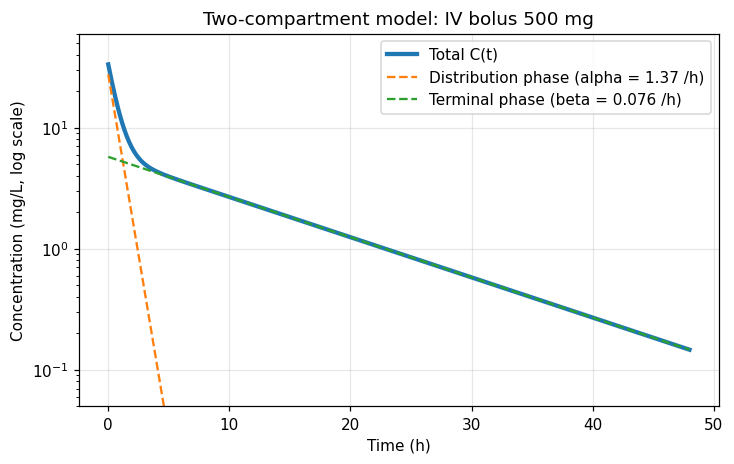

In [4]:
t = np.linspace(0, 48, 1000)
c = m.two_comp_iv(t, dose, V1, k10, k12, k21)

alpha, beta = p["alpha (1/h)"], p["beta (1/h)"]
A, B = p["A (mg/L)"], p["B (mg/L)"]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.semilogy(t, c, lw=2.8, label="Total C(t)")
ax.semilogy(t, A * np.exp(-alpha * t), "--", label=f"Distribution phase (alpha = {alpha:.2f} /h)")
ax.semilogy(t, B * np.exp(-beta * t), "--", label=f"Terminal phase (beta = {beta:.3f} /h)")
ax.set_ylim(0.05, 60)
ax.set_xlabel("Time (h)"); ax.set_ylabel("Concentration (mg/L, log scale)")
ax.set_title("Two-compartment model: IV bolus 500 mg")
ax.legend(); plt.show()

## 3. Validation against a numerical ODE solver

The analytical solution should match a numerical integration of the compartment
differential equations. The ODE solver also gives the **peripheral** compartment.

Analytical and numerical solutions agree.


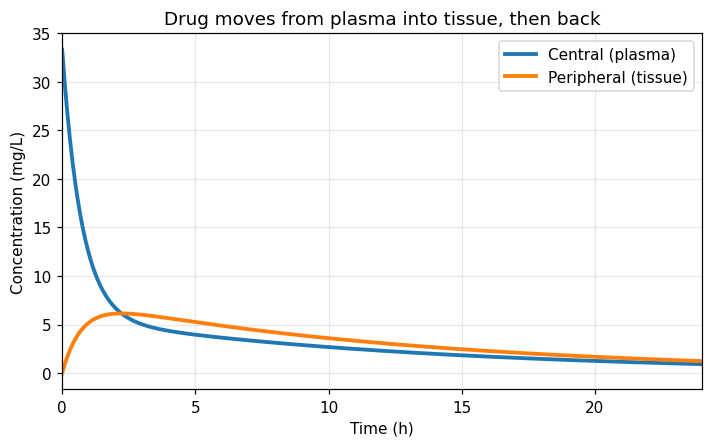

In [5]:
t_ode, c1, c2 = m.two_comp_ode(t, dose, V1, k10, k12, k21)
assert np.allclose(c1, c, rtol=1e-6, atol=1e-8)
print("Analytical and numerical solutions agree.")

plt.figure(figsize=(7.5, 4.2))
plt.plot(t_ode, c1, lw=2.5, label="Central (plasma)")
plt.plot(t_ode, c2, lw=2.5, label="Peripheral (tissue)")
plt.xlim(0, 24)
plt.xlabel("Time (h)"); plt.ylabel("Concentration (mg/L)")
plt.title("Drug moves from plasma into tissue, then back")
plt.legend(); plt.show()

### AUC check
The AUC from the data must equal `Dose / CL`, and also `A/alpha + B/beta`.

In [6]:
tt = np.linspace(0, 500, 500001)
cc = m.two_comp_iv(tt, dose, V1, k10, k12, k21)
print(f"AUC numerical      : {trapz(cc, tt):.2f} mg.h/L")
print(f"AUC = Dose / CL    : {p['AUC (mg.h/L)']:.2f} mg.h/L")
print(f"AUC = A/alpha+B/beta: {A / alpha + B / beta:.2f} mg.h/L")

AUC numerical      : 95.24 mg.h/L
AUC = Dose / CL    : 95.24 mg.h/L
AUC = A/alpha+B/beta: 95.24 mg.h/L


## 4. Why one compartment is not enough

Fitting a one-compartment model to a two-compartment drug fails whichever
volume we choose: using `V1` misses the terminal phase, using `Vss` misses the early phase.

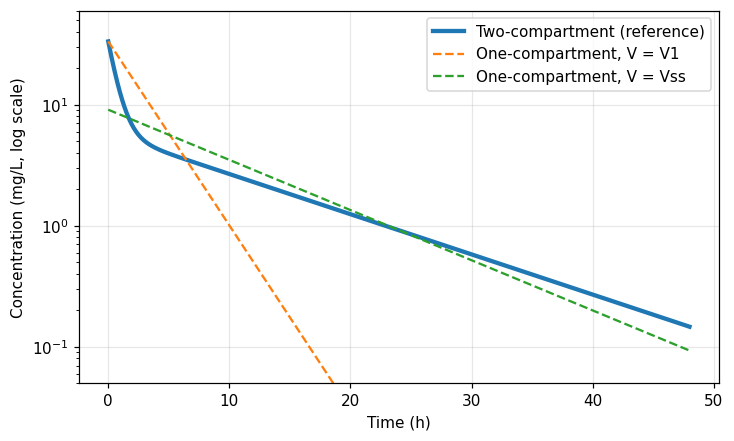

In [7]:
CL = p["CL (L/h)"]
Vss = p["Vss (L)"]

c_one_v1 = m.one_comp_iv(t, dose, V1, CL / V1)
c_one_vss = m.one_comp_iv(t, dose, Vss, CL / Vss)

plt.figure(figsize=(7.5, 4.4))
plt.semilogy(t, c, lw=2.8, label="Two-compartment (reference)")
plt.semilogy(t, c_one_v1, "--", label="One-compartment, V = V1")
plt.semilogy(t, c_one_vss, "--", label="One-compartment, V = Vss")
plt.ylim(0.05, 60)
plt.xlabel("Time (h)"); plt.ylabel("Concentration (mg/L, log scale)")
plt.legend(); plt.show()

## 5. How the distribution rate changes the profile

A larger `k12` means faster and more extensive movement into tissue,
so the initial drop is steeper and the terminal phase starts later.

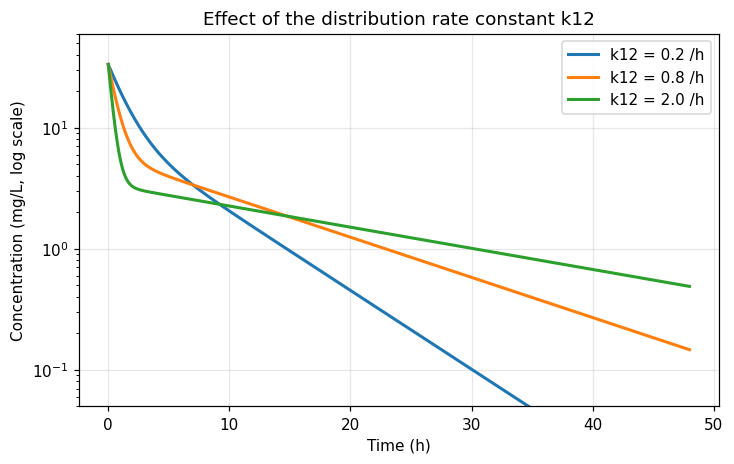

In [8]:
plt.figure(figsize=(7.5, 4.4))
for k12_test in (0.2, 0.8, 2.0):
    c_test = m.two_comp_iv(t, dose, V1, k10, k12_test, k21)
    plt.semilogy(t, c_test, lw=2, label=f"k12 = {k12_test} /h")
plt.ylim(0.05, 60)
plt.xlabel("Time (h)"); plt.ylabel("Concentration (mg/L, log scale)")
plt.title("Effect of the distribution rate constant k12")
plt.legend(); plt.show()

## 6. Method of residuals (peeling)

In practice we only have concentration measurements, not the parameters.
The classic graphical method recovers them in two steps:

1. Fit a straight line to the **late** points on a semi-log plot: this gives `beta` and `B`.
2. Subtract that line from the **early** points and fit again: this gives `alpha` and `A`.

In [9]:
t_obs = np.array([0.05, 0.15, 0.25, 0.5, 0.75, 1, 1.5, 2, 4, 6, 8, 12, 16, 24, 36, 48])
c_obs = m.two_comp_iv(t_obs, dose, V1, k10, k12, k21)

# Step 1: terminal phase
late = t_obs >= 12
slope, intercept = np.polyfit(t_obs[late], np.log(c_obs[late]), 1)
beta_est, B_est = -slope, np.exp(intercept)

# Step 2: residuals on the early phase
resid = c_obs - B_est * np.exp(-beta_est * t_obs)
early = t_obs <= 1.5
slope2, intercept2 = np.polyfit(t_obs[early], np.log(resid[early]), 1)
alpha_est, A_est = -slope2, np.exp(intercept2)

pd.DataFrame(
    {"true": [alpha, beta, A, B], "estimated": [alpha_est, beta_est, A_est, B_est]},
    index=["alpha (1/h)", "beta (1/h)", "A (mg/L)", "B (mg/L)"],
).round(4)

,true,estimated
alpha (1/h),1.3736,1.3736
beta (1/h),0.0764,0.0764
A (mg/L),27.5884,27.5884
B (mg/L),5.7450,5.7450


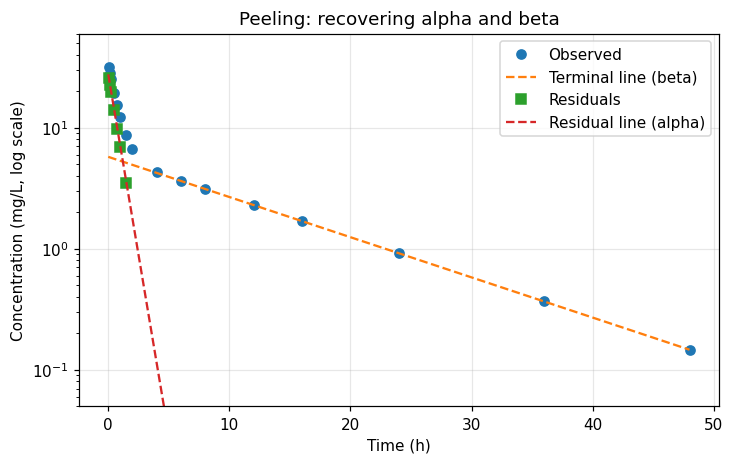

In [10]:
plt.figure(figsize=(7.5, 4.4))
plt.semilogy(t_obs, c_obs, "o", label="Observed")
plt.semilogy(t, B_est * np.exp(-beta_est * t), "--", label="Terminal line (beta)")
plt.semilogy(t_obs[early], resid[early], "s", label="Residuals")
plt.semilogy(t, A_est * np.exp(-alpha_est * t), "--", label="Residual line (alpha)")
plt.ylim(0.05, 60)
plt.xlabel("Time (h)"); plt.ylabel("Concentration (mg/L, log scale)")
plt.title("Peeling: recovering alpha and beta")
plt.legend(); plt.show()

## Takeaways
- Two-compartment drugs show a **biexponential** decline: distribution (`alpha`) then elimination (`beta`).
- Clearance is `CL = k10 * V1`, and the total distribution volume at steady state is `Vss = V1 + V2`.
- A one-compartment model cannot describe both phases with a single volume.
- The terminal half-life (`ln 2 / beta`) is usually the one reported in drug labels.

**Next:** notebook 03 links concentration to effect with the sigmoid Emax model (PK/PD).